# Setup & Load Untouched Raw Data (Kaggle CSV)

In [1]:
import os
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score, average_precision_score, f1_score,
    classification_report, precision_recall_curve
)
from lightgbm import LGBMClassifier
import shap

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

# Anchor working directory to day-09-insurance-cross-sell/src
PROJECT_SRC = r"C:\Users\adjis\github\100-days-real-world-ml\day-09-insurance-cross-sell\src"
if os.path.exists(PROJECT_SRC):
    os.chdir(PROJECT_SRC)
os.makedirs("outputs", exist_ok=True)

CSV_PATH = "../data/raw/train.csv"
df_raw = pd.read_csv(CSV_PATH)
print(f"Working directory : {os.getcwd()}")
print(f"Raw Dataset Shape : {df_raw.shape[0]:,} rows, {df_raw.shape[1]} columns")
df_raw.head()

C:\Users\adjis\anaconda3\envs\100-days-real-world-ml\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Working directory : C:\Users\adjis\github\100-days-real-world-ml\day-09-insurance-cross-sell\src
Raw Dataset Shape : 381,109 rows, 12 columns


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


# EDA 1: Schema, Duplicates, Near-Constant Features & False-Numeric ID Audit

In [2]:
print(f"Total Missing Values : {df_raw.isnull().sum().sum()}")
print(f"Exact Duplicate Rows : {df_raw.duplicated().sum()}")
print(f"Unique 'id' count    : {df_raw['id'].nunique():,} (100% unique primary key)")

audit_records = []
for col in df_raw.columns:
    audit_records.append({
        "Column": col,
        "Dtype": str(df_raw[col].dtype),
        "Unique_Values": df_raw[col].nunique(),
        "Top_Value": df_raw[col].mode()[0],
        "Top_Value_Pct (%)": round((df_raw[col] == df_raw[col].mode()[0]).mean() * 100, 2),
        "Sample_Values": str(df_raw[col].unique()[:3]),
    })
display(pd.DataFrame(audit_records))

# Inspect Annual_Premium baseline spike (e.g., 2630.0)
print("\nTop 5 Most Frequent Annual_Premium Values (Checking Statutory Baseline Spike):")
display(df_raw["Annual_Premium"].value_counts().head(5).to_frame("Policyholder_Count"))

Total Missing Values : 0
Exact Duplicate Rows : 0
Unique 'id' count    : 381,109 (100% unique primary key)


,Column,Dtype,Unique_Values,Top_Value,Top_Value_Pct (%),Sample_Values
0,id,int64,381109,1,0.00,[1 2 3]
1,Gender,str,2,Male,54.08,"<StringArray>\n['Male', 'Female']\nLength: 2, ..."
2,Age,int64,66,24,6.81,[44 76 47]
3,Driving_License,int64,2,1,99.79,[1 0]
4,Region_Code,float64,53,28.0,27.92,[28. 3. 11.]
5,Previously_Insured,int64,2,0,54.18,[0 1]
6,Vehicle_Age,str,3,1-2 Year,52.56,"<StringArray>\n['> 2 Years', '1-2 Year', '< 1 ..."
7,Vehicle_Damage,str,2,Yes,50.49,"<StringArray>\n['Yes', 'No']\nLength: 2, dtype..."
8,Annual_Premium,float64,48838,2630.0,17.02,[40454. 33536. 38294.]
9,Policy_Sales_Channel,float64,155,152.0,35.37,[ 26. 152. 160.]



Top 5 Most Frequent Annual_Premium Values (Checking Statutory Baseline Spike):


,Policyholder_Count
Annual_Premium,
2630.0,64877
69856.0,140
39008.0,41
45179.0,38
38287.0,38


# EDA 2: Class Imbalance, IQR Outliers & Behavioral Interaction Drivers

Target Variable ('Response') Distribution (0 = Not Interested, 1 = Interested):


,Count,Percentage (%)
Response,,
0,334399,87.74
1,46710,12.26



Conversion Rate (%) by Previously_Insured & Vehicle_Damage Interaction:


,Previously_Insured,Vehicle_Damage,count,Conversion_Rate_%
0,0,No,23990,3.79
1,0,Yes,182491,25.01
2,1,No,164706,0.04
3,1,Yes,9922,0.87


,count,mean,std,min,50%,max,skewness,IQR_Outliers
Age,381109.0,38.82,15.51,20.0,36.0,85.0,0.67,0
Annual_Premium,381109.0,30564.39,17213.16,2630.0,31669.0,540165.0,1.77,10320
Vintage,381109.0,154.35,83.67,10.0,154.0,299.0,0.00,0


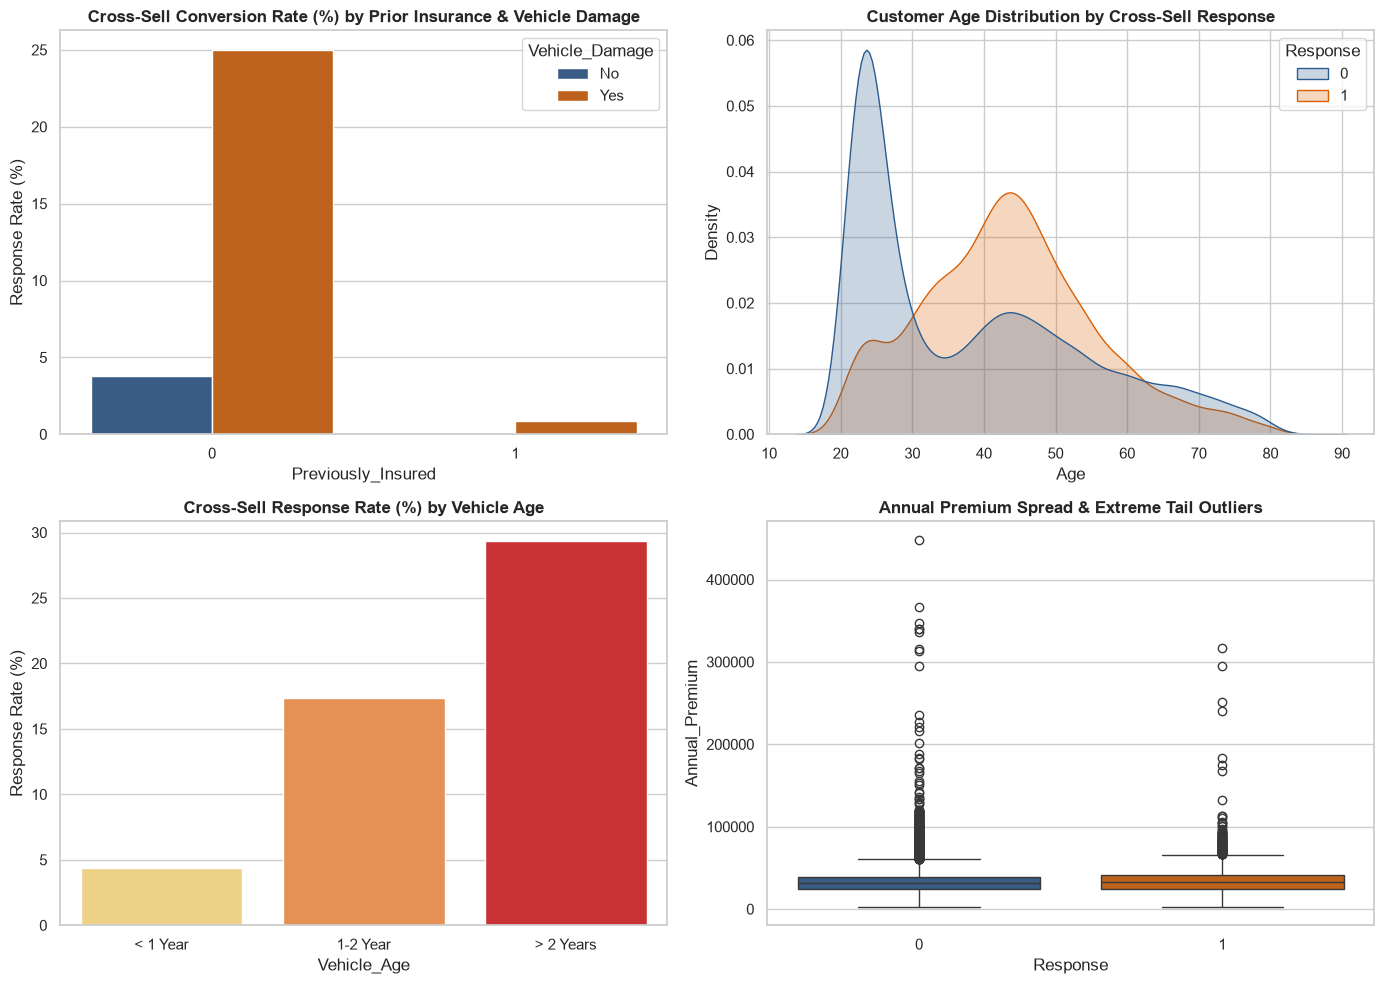

In [3]:
print("Target Variable ('Response') Distribution (0 = Not Interested, 1 = Interested):")
display(pd.DataFrame({
    "Count": df_raw["Response"].value_counts(),
    "Percentage (%)": (df_raw["Response"].value_counts(normalize=True) * 100).round(2)
}))

# Cross-tabulating the two strongest business drivers: Previously_Insured x Vehicle_Damage
print("\nConversion Rate (%) by Previously_Insured & Vehicle_Damage Interaction:")
interaction_ct = (df_raw.groupby(["Previously_Insured", "Vehicle_Damage"])["Response"].agg(["count", "mean"]).reset_index())
interaction_ct["Conversion_Rate_%"] = (interaction_ct["mean"] * 100).round(2)
display(interaction_ct[["Previously_Insured", "Vehicle_Damage", "count", "Conversion_Rate_%"]])

# Numerical summary & IQR Outliers
num_audit_cols = ["Age", "Annual_Premium", "Vintage"]
desc = df_raw[num_audit_cols].describe().T[["count", "mean", "std", "min", "50%", "max"]]
desc["skewness"] = df_raw[num_audit_cols].skew()
desc["IQR_Outliers"] = [
    ((s < s.quantile(0.25) - 1.5 * (s.quantile(0.75) - s.quantile(0.25))) |
     (s > s.quantile(0.75) + 1.5 * (s.quantile(0.75) - s.quantile(0.25)))).sum()
    for s in [df_raw[c] for c in num_audit_cols]
]
display(desc.round(2))

# Visual EDA Dashboard
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Conversion Rate by Previously_Insured & Vehicle_Damage
sns.barplot(
    data=interaction_ct, x="Previously_Insured", y="Conversion_Rate_%",
    hue="Vehicle_Damage", palette=["#2b5c8f", "#d95f02"], ax=axes[0, 0]
)
axes[0, 0].set_title("Cross-Sell Conversion Rate (%) by Prior Insurance & Vehicle Damage", fontweight="bold")
axes[0, 0].set_ylabel("Response Rate (%)")

# Plot 2: Age Distribution by Response
sns.kdeplot(
    data=df_raw.sample(50000, random_state=42), x="Age", hue="Response",
    fill=True, common_norm=False, palette=["#2b5c8f", "#d95f02"], ax=axes[0, 1]
)
axes[0, 1].set_title("Customer Age Distribution by Cross-Sell Response", fontweight="bold")

# Plot 3: Conversion Rate by Vehicle Age
veh_order = ["< 1 Year", "1-2 Year", "> 2 Years"]
veh_resp = df_raw.groupby("Vehicle_Age")["Response"].mean().loc[veh_order] * 100
sns.barplot(x=veh_resp.index, y=veh_resp.values, palette="YlOrRd", ax=axes[1, 0])
axes[1, 0].set_title("Cross-Sell Response Rate (%) by Vehicle Age", fontweight="bold")
axes[1, 0].set_ylabel("Response Rate (%)")

# Plot 4: Annual_Premium Boxplot Showing Right Skew & Outliers
sns.boxplot(data=df_raw.sample(50000, random_state=42), x="Response", y="Annual_Premium", palette=["#2b5c8f", "#d95f02"], ax=axes[1, 1])
axes[1, 1].set_title("Annual Premium Spread & Extreme Tail Outliers", fontweight="bold")

plt.tight_layout()
plt.savefig("outputs/eda_insurance_cross_sell.png", dpi=150)
plt.show()

# Evidence-Based Data Cleaning

In [4]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 'id' (100% unique primary key with zero predictive signal).
2. Cast 'Region_Code' and 'Policy_Sales_Channel' from float64 to integer/categorical IDs
   so linear models do not treat nominal region/channel IDs as continuous magnitudes.
3. Preserve 'Annual_Premium' outliers (no row dropping) and handle right skewness via log1p
   + an explicit binary flag for the statutory minimum baseline (2630.0) in Cell 5.
"""
df_clean = df_raw.drop(columns=["id"]).copy()
df_clean["Region_Code"] = df_clean["Region_Code"].astype(int).astype(str)
df_clean["Policy_Sales_Channel"] = df_clean["Policy_Sales_Channel"].astype(int).astype(str)
df_clean["Vehicle_Damage"] = df_clean["Vehicle_Damage"].map({"Yes": 1, "No": 0}).astype(int)

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Positive Rate: {df_clean['Response'].mean():.2%}")

Cleaned Dataset Shape: 381,109 rows, 11 columns | Positive Rate: 12.26%


# Evidence-Based Data Cleaning

In [5]:
"""
Cleaning Rules Driven by EDA Findings:
1. Drop 'id' (100% unique primary key with zero predictive signal).
2. Cast 'Region_Code' and 'Policy_Sales_Channel' from float64 to integer/categorical IDs
   so linear models do not treat nominal region/channel IDs as continuous magnitudes.
3. Preserve 'Annual_Premium' outliers (no row dropping) and handle right skewness via log1p
   + an explicit binary flag for the statutory minimum baseline (2630.0) in Cell 5.
"""
df_clean = df_raw.drop(columns=["id"]).copy()
df_clean["Region_Code"] = df_clean["Region_Code"].astype(int).astype(str)
df_clean["Policy_Sales_Channel"] = df_clean["Policy_Sales_Channel"].astype(int).astype(str)
df_clean["Vehicle_Damage"] = df_clean["Vehicle_Damage"].map({"Yes": 1, "No": 0}).astype(int)

print(f"Cleaned Dataset Shape: {df_clean.shape[0]:,} rows, {df_clean.shape[1]} columns | Positive Rate: {df_clean['Response'].mean():.2%}")

Cleaned Dataset Shape: 381,109 rows, 11 columns | Positive Rate: 12.26%


# Domain Feature Engineering & Leak-Free Frequency Encoding + Preprocessing

In [6]:
df_feat = df_clean.copy()

# 1. Domain interaction flag discovered in EDA Cell 3
df_feat["is_uninsured_and_damaged"] = (
    (df_feat["Previously_Insured"] == 0) & (df_feat["Vehicle_Damage"] == 1)
).astype(int)

# 2. Statutory baseline premium indicator & log-compressed premium
min_premium = df_feat["Annual_Premium"].min()
df_feat["is_baseline_premium"] = (df_feat["Annual_Premium"] == min_premium).astype(int)
df_feat["log_annual_premium"] = np.log1p(df_feat["Annual_Premium"])

# 3. Age bracket & premium-to-vintage ratio
df_feat["is_prime_buying_age"] = df_feat["Age"].between(30, 55).astype(int)
df_feat["premium_per_vintage_day"] = df_feat["Annual_Premium"] / (df_feat["Vintage"] + 1.0)

X = df_feat.drop(columns=["Response"])
y = df_feat["Response"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Leak-free frequency & out-of-fold target mean encoding for high-cardinality nominal IDs
for id_col in ["Region_Code", "Policy_Sales_Channel"]:
    freq_map = X_train[id_col].value_counts(normalize=True)
    X_train[f"{id_col}_freq"] = X_train[id_col].map(freq_map).fillna(0.0)
    X_test[f"{id_col}_freq"] = X_test[id_col].map(freq_map).fillna(0.0)

    # Smoothed target encoding computed strictly on X_train
    global_mean = y_train.mean()
    stats = pd.DataFrame({"col": X_train[id_col], "y": y_train}).groupby("col")["y"].agg(["count", "mean"])
    smooth = 50.0
    te_map = (stats["count"] * stats["mean"] + smooth * global_mean) / (stats["count"] + smooth)
    X_train[f"{id_col}_te"] = X_train[id_col].map(te_map).fillna(global_mean)
    X_test[f"{id_col}_te"] = X_test[id_col].map(te_map).fillna(global_mean)

X_train.drop(columns=["Region_Code", "Policy_Sales_Channel"], inplace=True)
X_test.drop(columns=["Region_Code", "Policy_Sales_Channel"], inplace=True)

ordinal_cols = ["Vehicle_Age"]
nominal_cols = ["Gender"]
num_cols = [c for c in X_train.columns if c not in ordinal_cols + nominal_cols]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("ord", OrdinalEncoder(categories=[["< 1 Year", "1-2 Year", "> 2 Years"]]), ordinal_cols),
    ("nom", OneHotEncoder(drop="if_binary", sparse_output=False), nominal_cols),
])

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

Train Shape: (304887, 17) | Test Shape: (76222, 17)


# Model Benchmarking (Logistic Regression vs. LightGBM) & Top-20% Decile Capture Lift

In [7]:
def find_optimal_f1_threshold(y_true, y_probs):
    precisions, recalls, thresholds = precision_recall_curve(y_true, y_probs)
    f1_scores = (2 * precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])
    return float(thresholds[best_idx])

def top_k_capture_rate(y_true, y_probs, top_frac=0.20):
    """Calculate what % of all true buyers are captured if telemarketers call only the top K% ranked leads."""
    n_top = int(len(y_true) * top_frac)
    top_indices = np.argsort(y_probs)[::-1][:n_top]
    return float(y_true[top_indices].sum() / y_true.sum()) * 100.0

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    "Logistic Regression (Balanced Baseline)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(class_weight="balanced", max_iter=1000, n_jobs=-1, random_state=42)),
    ]),
    "LightGBM (Cross-Sell Propensity Engine)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LGBMClassifier(
            n_estimators=400,
            learning_rate=0.05,
            num_leaves=31,
            max_depth=7,
            subsample=0.8,
            colsample_bytree=0.8,
            scale_pos_weight=np.sqrt(scale_pos_weight),
            n_jobs=-1,
            random_state=42,
            verbose=-1,
        )),
    ]),
}

best_model, best_roc_auc = None, 0.0

for name, pipeline in models.items():
    pipeline.fit(X_train, y_train)
    y_probs = pipeline.predict_proba(X_test)[:, 1]
    opt_thresh = find_optimal_f1_threshold(y_test, y_probs)
    y_pred = (y_probs >= opt_thresh).astype(int)

    roc_auc = roc_auc_score(y_test, y_probs)
    pr_auc = average_precision_score(y_test, y_probs)
    capture_20 = top_k_capture_rate(y_test, y_probs, top_frac=0.20)

    print(f"\n---> {name}")
    print(f"ROC-AUC : {roc_auc:.4f} | PR-AUC : {pr_auc:.4f} | Top-20% Call Capture : {capture_20:.2f}% | Threshold : {opt_thresh:.4f}")
    print(classification_report(y_test, y_pred, target_names=["Not Interested (0)", "Interested (1)"]))

    if roc_auc > best_roc_auc:
        best_roc_auc = roc_auc
        best_model = pipeline

joblib.dump(best_model, "outputs/best_insurance_cross_sell_model.joblib")


---> Logistic Regression (Balanced Baseline)
ROC-AUC : 0.8497 | PR-AUC : 0.3424 | Top-20% Call Capture : 55.74% | Threshold : 0.6633
                    precision    recall  f1-score   support

Not Interested (0)       0.96      0.78      0.86     66880
    Interested (1)       0.32      0.76      0.45      9342

          accuracy                           0.77     76222
         macro avg       0.64      0.77      0.65     76222
      weighted avg       0.88      0.77      0.81     76222


---> LightGBM (Cross-Sell Propensity Engine)
ROC-AUC : 0.8582 | PR-AUC : 0.3704 | Top-20% Call Capture : 58.02% | Threshold : 0.4158
                    precision    recall  f1-score   support

Not Interested (0)       0.96      0.77      0.86     66880
    Interested (1)       0.32      0.79      0.46      9342

          accuracy                           0.77     76222
         macro avg       0.64      0.78      0.66     76222
      weighted avg       0.89      0.77      0.81     76222



['outputs/best_insurance_cross_sell_model.joblib']

# Fast SHAP Explainability (Subsampled for Instant Local Execution)

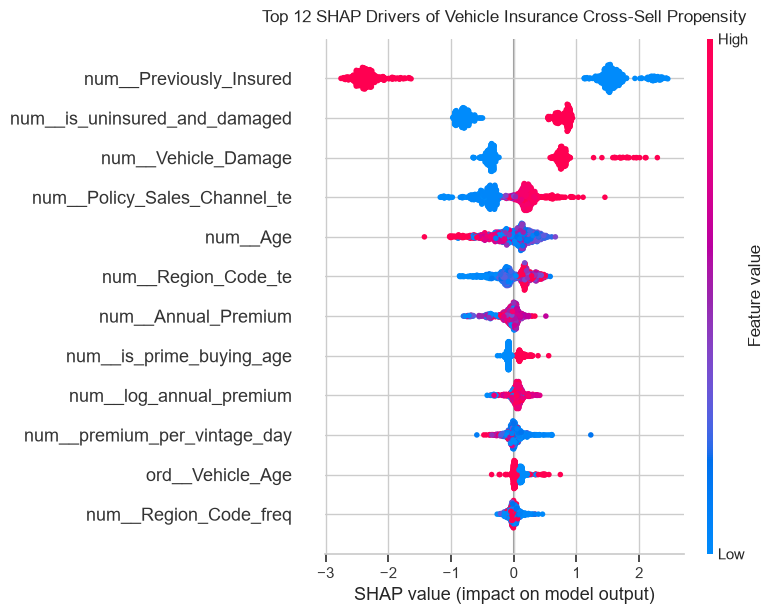

In [8]:
lgbm_pipe = models["LightGBM (Cross-Sell Propensity Engine)"]

X_test_sample = X_test.sample(800, random_state=42)
X_test_transformed = lgbm_pipe.named_steps["preprocessor"].transform(X_test_sample)
feature_names = lgbm_pipe.named_steps["preprocessor"].get_feature_names_out()

explainer = shap.TreeExplainer(lgbm_pipe.named_steps["classifier"])
shap_values = explainer.shap_values(X_test_transformed)
shap_vals_to_plot = shap_values[1] if isinstance(shap_values, list) else shap_values

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals_to_plot, X_test_transformed, feature_names=feature_names, show=False, max_display=12)
plt.title("Top 12 SHAP Drivers of Vehicle Insurance Cross-Sell Propensity", fontsize=12, pad=12)
plt.tight_layout()
plt.savefig("outputs/shap_insurance_cross_sell.png", dpi=150)
plt.show()